# RAG Part 1 — Experiment 3: retrieval on the claim-verification gold set

Expt 2 scored retrieval with FAQ questions whose wording appears in the gold chunk. Here the queries are **claims**
from `eval/goldset.jsonl` (built by `eval/build_goldset.py`, spot-checked: 50/50 correct):

| label | categories | what retrieval must do |
|---|---|---|
| SUPPORTED | `supported_rule`, `supported_synth` | find the chunk that states the claim |
| CONTRADICTED | `contradicted_number`, `contradicted_ticker` | find the chunk that **refutes** it (the true figure) |
| NOT_ENOUGH_EVIDENCE | `nee_period_shift` | find the source (it covers another period; the verifier must notice) |
| NOT_ENOUGH_EVIDENCE | `nee_absent`, `nee_unstated` | nothing to find: retrieval should *signal* that (low scores) |

Gold labels are graded per chunk (2 = states the fact, 1 = same entity + metric). Collection: clean Strategy B
(`ppp_all-mpnet-base-v2_B_clean`); the gold chunk ids are Strategy-B ids, so Strategy A is not scored here.

**Configs** (from expt 2): bi-encoder top 50 → optional cross-encoder rerank (MiniLM-L6 / bge-reranker-base) →
top 10 with or without a cap of 2 chunks per article (the LLM would get the top 5). Leaked FAQ chunks
(`exclude_chunk_ids`) are dropped before selection. Nothing is tuned for the retrieval tables, so they use all items;
the NOT_ENOUGH_EVIDENCE threshold is tuned on **dev** and reported on **test**.

In [1]:
import os
import sys

os.environ.setdefault("HF_HUB_OFFLINE", "1")  # models are cached; skip the Hub check
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
sys.path.insert(0, "..")

import time
from collections import Counter

import chromadb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import CrossEncoder, SentenceTransformer

from eval.common import K, K_FETCH, auroc, drop_excluded, fetch, load_goldset, rerank, score_item, select

pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 220)

EMBEDDING_MODEL = "sentence-transformers/all-mpnet-base-v2"
COLLECTION = "ppp_all-mpnet-base-v2_B_clean"
RERANKERS = {"MiniLM-L6": "cross-encoder/ms-marco-MiniLM-L-6-v2", "bge-reranker-base": "BAAI/bge-reranker-base"}
CHROMA_PATH, DATA_DIR, GOLDSET = "../.chroma", "../data/processed", "../eval/goldset.jsonl"
K_EVAL = 10  # results scored per query (the LLM gets the top K=5)
CAPS = [None, 2]
ANSWERABLE = ["supported_rule", "supported_synth", "contradicted_number", "contradicted_ticker", "nee_period_shift"]
NO_EVIDENCE = ["nee_absent", "nee_unstated"]
CATEGORY_ORDER = ANSWERABLE + NO_EVIDENCE
print(f"K={K}, K_FETCH={K_FETCH}, K_EVAL={K_EVAL}")

/Users/zhaoweikennethlim/Desktop/fin-audit-guard-rag/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


K=5, K_FETCH=50, K_EVAL=10


## 1. Gold set

In [2]:
items = load_goldset(GOLDSET)
gs = pd.DataFrame(items)
counts = pd.crosstab(gs.category, gs.split, margins=True).reindex(CATEGORY_ORDER + ["All"])
counts["grade-2 chunks (median)"] = gs.groupby("category").gold_chunk_ids.agg(
    lambda s: np.median([sum(g == 2 for g in d.values()) for d in s]) if len(s) else np.nan)
counts

split,dev,test,All,grade-2 chunks (median)
category,,,,
supported_rule,8,12,20,2.0
supported_synth,36,39,75,1.0
contradicted_number,25,25,50,1.0
contradicted_ticker,4,0,4,2.0
nee_period_shift,2,1,3,1.0
nee_absent,9,9,18,0.0
nee_unstated,10,10,20,0.0
All,94,96,190,NaN


## 2. Candidates: bi-encoder top 50, then each reranker over the same 50

In [3]:
model = SentenceTransformer(EMBEDDING_MODEL)
col = chromadb.PersistentClient(path=CHROMA_PATH).get_collection(COLLECTION)
claims = [it["claim"] for it in items]

t = time.time()
query_embs = model.encode(claims, normalize_embeddings=True, batch_size=64)
base = [drop_excluded(c, it) for c, it in zip(fetch(col, query_embs, k_fetch=K_FETCH), items)]
print(f"{col.name}: {col.count():,} chunks | fetched {K_FETCH} for {len(items)} claims in {time.time() - t:.1f}s")

candidates, timings = {"bi-encoder": base}, {}
for name, path in RERANKERS.items():
    ce = CrossEncoder(path, max_length=512)
    t = time.time()
    candidates[f"+ {name}"] = rerank(ce, claims, base, depth=K_FETCH)
    timings[name] = round(time.time() - t, 1)
    print(f"{name} on {ce.model.device}: {len(items) * K_FETCH:,} pairs in {timings[name]}s")

ppp_all-mpnet-base-v2_B_clean: 17,045 chunks | fetched 50 for 190 claims in 2.1s


MiniLM-L6 on mps:0: 9,500 pairs in 26.8s


bge-reranker-base on mps:0: 9,500 pairs in 152.5s


## 3. Per-item scores for every config

`top1` is the score the pipeline would use to decide whether *any* evidence exists: the cross-encoder score of the
best chunk after reranking, or the cosine similarity for the bi-encoder.

In [4]:
def config_name(pipe: str, cap) -> str:
    return pipe + (f" | cap {cap}/doc" if cap else "")


CONFIGS = [config_name(p, c) for p in candidates for c in CAPS]
rows = []
for pipe, cand_lists in candidates.items():
    for cap in CAPS:
        for it, cands in zip(items, cand_lists):
            top = select(cands, k=K_EVAL, per_doc_cap=cap)
            row = {"config": config_name(pipe, cap), "item_id": it["item_id"], "category": it["category"],
                   "label": it["label"], "split": it["split"], "generator": it["generator"],
                   "perturbed_from": it.get("perturbed_from"), "perturbation": it.get("perturbation"),
                   "top1": top[0].get("ce", top[0]["sim"]),
                   "top_chunk_ids": [c["chunk_id"] for c in top]}
            if it["gold_chunk_ids"]:
                row.update(score_item(top, it, ks=(1, 5, 10)))
            rows.append(row)
per_item = pd.DataFrame(rows)
per_item["config"] = pd.Categorical(per_item["config"], CONFIGS, ordered=True)
print(per_item.shape)

(1140, 24)


## 4. Retrieval quality on answerable claims

Grade-2 recall / MRR (does the chunk that states or refutes the fact come back, and how high?), plus nDCG@5 and
precision@5 with graded labels.

In [5]:
METRICS = ["hit@1", "hit@5", "recall@5", "recall@10", "rr", "nDCG@5", "precision@5"]
ans = per_item[per_item.category.isin(ANSWERABLE)]
overall = ans.groupby("config", observed=True)[METRICS].mean().rename(columns={"rr": "MRR"}).round(3)
overall["n"] = ans.groupby("config", observed=True).size()
overall

,hit@1,hit@5,recall@5,recall@10,MRR,nDCG@5,precision@5,n
config,,,,,,,,
bi-encoder,0.395,0.625,0.501,0.616,0.506,0.444,0.245,152
bi-encoder | cap 2/doc,0.395,0.632,0.488,0.508,0.499,0.433,0.226,152
+ MiniLM-L6,0.671,0.849,0.770,0.815,0.750,0.685,0.338,152
+ MiniLM-L6 | cap 2/doc,0.671,0.822,0.713,0.721,0.743,0.642,0.282,152
+ bge-reranker-base,0.770,0.855,0.776,0.812,0.806,0.721,0.339,152
+ bge-reranker-base | cap 2/doc,0.770,0.849,0.743,0.746,0.803,0.689,0.289,152


In [6]:
by_cat = (ans.groupby(["config", "category"], observed=True)[METRICS].mean().rename(columns={"rr": "MRR"}).round(3))
n_cat = ans[ans.config == CONFIGS[0]].category.value_counts()
print("items per category:", n_cat.reindex(ANSWERABLE).to_dict())
print("\nMRR by category")
display(by_cat["MRR"].unstack("category")[ANSWERABLE])
print("hit@5 by category")
display(by_cat["hit@5"].unstack("category")[ANSWERABLE])

items per category: {'supported_rule': 20, 'supported_synth': 75, 'contradicted_number': 50, 'contradicted_ticker': 4, 'nee_period_shift': 3}

MRR by category


category,supported_rule,supported_synth,contradicted_number,contradicted_ticker,nee_period_shift
config,,,,,
bi-encoder,0.565,0.482,0.482,0.833,0.667
bi-encoder | cap 2/doc,0.571,0.468,0.480,0.833,0.667
+ MiniLM-L6,0.808,0.742,0.745,0.500,1.000
+ MiniLM-L6 | cap 2/doc,0.792,0.739,0.733,0.500,1.000
+ bge-reranker-base,0.824,0.818,0.768,0.833,1.000
+ bge-reranker-base | cap 2/doc,0.817,0.818,0.768,0.750,1.000


hit@5 by category


category,supported_rule,supported_synth,contradicted_number,contradicted_ticker,nee_period_shift
config,,,,,
bi-encoder,0.80,0.587,0.58,1.00,0.667
bi-encoder | cap 2/doc,0.85,0.573,0.60,1.00,0.667
+ MiniLM-L6,0.90,0.840,0.84,0.75,1.000
+ MiniLM-L6 | cap 2/doc,0.85,0.827,0.80,0.75,1.000
+ bge-reranker-base,0.85,0.853,0.84,1.00,1.000
+ bge-reranker-base | cap 2/doc,0.85,0.853,0.84,0.75,1.000


### 4b. LLM-written (synth) vs rule-based SUPPORTED claims

In [7]:
sup = per_item[per_item.label == "SUPPORTED"]
gen_cmp = sup.groupby(["config", "generator"], observed=True)[["hit@1", "hit@5", "recall@5", "rr"]].mean()
gen_cmp.rename(columns={"rr": "MRR"}).round(3).unstack("generator")

hit@1          hit@5       recall@5             MRR       
generator                       deepeval rules deepeval rules deepeval  rules deepeval  rules
config                                                                                       
bi-encoder                         0.387  0.35    0.587  0.80    0.493  0.522    0.482  0.565
bi-encoder | cap 2/doc             0.387  0.35    0.573  0.85    0.463  0.527    0.468  0.571
+ MiniLM-L6                        0.653  0.75    0.840  0.90    0.763  0.770    0.742  0.808
+ MiniLM-L6 | cap 2/doc            0.653  0.75    0.827  0.85    0.736  0.628    0.739  0.792
+ bge-reranker-base                0.787  0.80    0.853  0.85    0.772  0.747    0.818  0.824
+ bge-reranker-base | cap 2/doc    0.787  0.80    0.853  0.85    0.758  0.635    0.818  0.817

## 5. Paired gap: does a wrong number hide the refuting evidence?

Each CONTRADICTED / period-shift twin differs from its SUPPORTED source claim by one figure, fund or year. The gap is
twin − source on the same metric (negative = the twin's evidence is harder to retrieve). Ticker twins point at a
*different* fund's chunks, so they are reported separately.

In [8]:
pair_rows = []
for cfg in CONFIGS:
    m = per_item[per_item.config == cfg].set_index("item_id")
    for tid, tw in m[m.perturbed_from.notna()].iterrows():
        src = m.loc[tw.perturbed_from]
        pair_rows.append({"config": cfg, "twin": tid, "source": tw.perturbed_from, "perturbation": tw.perturbation,
                          **{f"{k} twin": tw[k] for k in ("recall@5", "rr")},
                          **{f"{k} source": src[k] for k in ("recall@5", "rr")},
                          "Δrecall@5": tw["recall@5"] - src["recall@5"], "ΔMRR": tw["rr"] - src["rr"]})
pairs = pd.DataFrame(pair_rows)
pairs["config"] = pd.Categorical(pairs["config"], CONFIGS, ordered=True)
gap = pairs.groupby(["config", "perturbation"], observed=True).agg(
    n=("twin", "size"), recall5_source=("recall@5 source", "mean"), recall5_twin=("recall@5 twin", "mean"),
    d_recall5=("Δrecall@5", "mean"), mrr_source=("rr source", "mean"), mrr_twin=("rr twin", "mean"),
    d_mrr=("ΔMRR", "mean"), twin_worse=("ΔMRR", lambda s: (s < 0).mean())).round(3)
gap

n  recall5_source  recall5_twin  d_recall5  mrr_source  mrr_twin  d_mrr  twin_worse
config                          perturbation                                                                                      
bi-encoder                      number        50           0.484         0.464     -0.020       0.469     0.482  0.013        0.10
                                period         3           0.500         0.500      0.000       0.667     0.667  0.000        0.00
                                ticker         4           1.000         1.000      0.000       0.646     0.833  0.188        0.25
bi-encoder | cap 2/doc          number        50           0.501         0.477     -0.023       0.463     0.480  0.017        0.04
                                period         3           0.500         0.500      0.000       0.667     0.667  0.000        0.00
                                ticker         4           0.750         0.875      0.125       0.646     0.833  0.188        0.25
+ MiniLM-L6                     number        50           0.796         0.790     -0.007       0.782     0.745 -0.037        0.06
                                period         3           1.000         1.000      0.000       1.000     1.000  0.000        0.00
                                ticker         4           1.000         0.500     -0.500       0.833     0.500 -0.333        0.50
+ MiniLM-L6 | cap 2/doc         number        50           0.754         0.714     -0.040       0.777     0.733 -0.043        0.06
                                period         3           0.833         1.000      0.167       1.000     1.000  0.000        0.00
                                ticker         4           0.750         0.500     -0.250       0.750     0.500 -0.250        0.50
+ bge-reranker-base             number        50           0.795         0.791     -0.004       0.817     0.768 -0.048        0.08
                                period         3           1.000         1.000      0.000       1.000     1.000  0.000        0.00
                                ticker         4           0.750         0.625     -0.125       0.786     0.833  0.048        0.25
+ bge-reranker-base | cap 2/doc number        50           0.772         0.769     -0.002       0.817     0.768 -0.048        0.08
                                period         3           1.000         1.000      0.000       1.000     1.000  0.000        0.00
                                ticker         4           0.625         0.500     -0.125       0.750     0.750  0.000        0.25

## 6. Can retrieval scores flag NOT_ENOUGH_EVIDENCE?

Positives = answerable SUPPORTED + CONTRADICTED claims (evidence exists); negatives = `nee_absent` + `nee_unstated`.
AUROC of `top1`; then a threshold chosen on **dev** (max TPR − FPR) and applied to **test**:
false-accept = no-evidence claim scored above the threshold; false-reject = answerable claim scored below it.
Period-shift claims are reported apart: their source *is* retrievable, so a score threshold should accept them and
the verifier has to catch the period.

In [9]:
def youden_threshold(pos, neg):
    cands = np.unique(np.concatenate([pos, neg]))
    return max(cands, key=lambda t: (pos >= t).mean() - (neg >= t).mean())


POS_CATS = ["supported_rule", "supported_synth", "contradicted_number", "contradicted_ticker"]
nee_rows = []
for cfg in CONFIGS:
    m = per_item[per_item.config == cfg]
    get = lambda split, cats: m[(m.split == split) & m.category.isin(cats)].top1.to_numpy()  # noqa: E731
    t = youden_threshold(get("dev", POS_CATS), get("dev", NO_EVIDENCE))
    pos_t, neg_t = get("test", POS_CATS), get("test", NO_EVIDENCE)
    shift = m[m.category == "nee_period_shift"].top1.to_numpy()
    nee_rows.append({"config": cfg, "AUROC dev": auroc(get("dev", POS_CATS), get("dev", NO_EVIDENCE)),
                     "AUROC test": auroc(pos_t, neg_t), "threshold (dev)": t,
                     "false-accept test": (neg_t >= t).mean(), "false-reject test": (pos_t < t).mean(),
                     "period-shift accepted": (shift >= t).mean(),
                     "n test pos/neg": f"{len(pos_t)}/{len(neg_t)}"})
nee = pd.DataFrame(nee_rows).set_index("config").round(3)
nee

,AUROC dev,AUROC test,threshold (dev),false-accept test,false-reject test,period-shift accepted,n test pos/neg
config,,,,,,,
bi-encoder,0.877,0.902,0.557,0.105,0.132,0.667,76/19
bi-encoder | cap 2/doc,0.877,0.902,0.557,0.105,0.132,0.667,76/19
+ MiniLM-L6,0.893,0.955,2.699,0.053,0.145,1.000,76/19
+ MiniLM-L6 | cap 2/doc,0.893,0.955,2.699,0.053,0.145,1.000,76/19
+ bge-reranker-base,0.958,0.960,0.200,0.105,0.066,1.000,76/19
+ bge-reranker-base | cap 2/doc,0.958,0.960,0.200,0.105,0.066,1.000,76/19


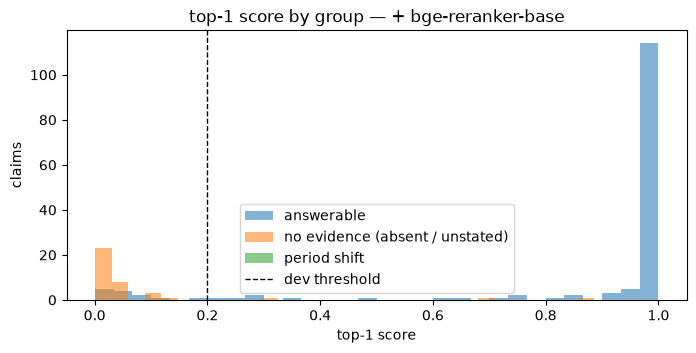

                     mean   50%   min   max
category                                   
supported_rule       0.84  0.99  0.06  1.00
supported_synth      0.92  1.00  0.00  1.00
contradicted_number  0.85  0.99  0.00  1.00
contradicted_ticker  0.28  0.09  0.05  0.90
nee_period_shift     1.00  1.00  1.00  1.00
nee_absent           0.08  0.02  0.00  0.89
nee_unstated         0.07  0.03  0.00  0.70


In [10]:
best_rr = nee["AUROC test"].idxmax()
m = per_item[per_item.config == best_rr]
fig, ax = plt.subplots(figsize=(8, 3.5))
for cats, lab in [(POS_CATS, "answerable"), (NO_EVIDENCE, "no evidence (absent / unstated)"),
                  (["nee_period_shift"], "period shift")]:
    ax.hist(m[m.category.isin(cats)].top1, bins=30, alpha=0.55, label=lab)
ax.axvline(nee.loc[best_rr, "threshold (dev)"], color="k", ls="--", lw=1, label="dev threshold")
ax.set(title=f"top-1 score by group — {best_rr}", xlabel="top-1 score", ylabel="claims")
ax.legend()
plt.show()
print(m.groupby("category", observed=True).top1.describe()[["mean", "50%", "min", "max"]].round(2).reindex(CATEGORY_ORDER))

## 7. Failure cases (best config by overall MRR)

Answerable claims whose grade-2 evidence is not in the top 10, with what came back instead — to separate real
retrieval misses from gold-label gaps.

In [11]:
chunks = pd.read_csv(f"{DATA_DIR}/chunks_B_structured_clean.csv", keep_default_na=False).set_index("chunk_id")
best = overall["MRR"].idxmax()
print("best config by MRR:", best)
by_id = {it["item_id"]: it for it in items}
miss = per_item[(per_item.config == best) & per_item.category.isin(ANSWERABLE) & (per_item["recall@10"] == 0)]
print(f"{len(miss)} of {len(ans[ans.config == best])} answerable claims have no grade-2 chunk in the top {K_EVAL}\n")


def label(cid):
    r = chunks.loc[cid]
    return f"{r.title[:60]} › {r.section[:40]}"


for _, r in miss.iterrows():
    it = by_id[r.item_id]
    print(f"[{r.item_id}] {it['claim'][:150]}")
    gold2 = [c for c, g in it["gold_chunk_ids"].items() if g == 2]
    print("   gold:", " | ".join(label(c) for c in gold2[:2]))
    for c in r.top_chunk_ids[:3]:
        print(f"   got {it['gold_chunk_ids'].get(c, 0)}: {label(c)}")

best config by MRR: + bge-reranker-base
21 of 152 answerable claims have no grade-2 chunk in the top 10

[supported_rule-004] The S&P 500 index fell -47% peak-to-trough between 2000 and 2002; -54% between 2007 and 2009; and -34% in the, thankfully brief, Covid crash of 2020.
   gold: MKAM ETF Review: The Strategy Behind MKAM ETF Review With St › Anxious investors
   got 0: A Complete History of Bull and Bear Markets: Key Lessons Lea › The Pandemic Bear Market and Current Mar
   got 0: Black Swan Events: Building Portfolios that Survive the Unex › COVID-19 Market Crash
   got 0: Lost Decade of the 2000s Myth | 8 Equity Asset Classes That  › US Small Cap Value = 2000 to 2010 Stella
[supported_rule-010] Poor 'ole 60/40 hobbles across the finish line below water with a CAGR of -0.67% and RISK of 13.34%.
   gold: iMGP DBi MANAGED FUTURES STRATEGY ETF | DBMF ETF Review › Quant 60/40 Portfolio vs Industry Standa | iMGP DBi MANAGED FUTURES STRATEGY ETF | DBMF ETF Review › Quant 60/40 Portfolio

## 8. Save

In [12]:
overall.reset_index().to_csv(f"{DATA_DIR}/expt3_retrieval_overall.csv", index=False)
by_cat.reset_index().to_csv(f"{DATA_DIR}/expt3_retrieval_by_category.csv", index=False)
gen_cmp.reset_index().to_csv(f"{DATA_DIR}/expt3_synth_vs_rule.csv", index=False)
gap.reset_index().to_csv(f"{DATA_DIR}/expt3_paired_gap.csv", index=False)
pairs.to_csv(f"{DATA_DIR}/expt3_paired_items.csv", index=False)
nee.reset_index().to_csv(f"{DATA_DIR}/expt3_nee_detection.csv", index=False)
per_item.drop(columns="top_chunk_ids").to_csv(f"{DATA_DIR}/expt3_per_item.csv", index=False)
print("saved expt3_*.csv to", DATA_DIR, "| reranking seconds:", timings)

saved expt3_*.csv to ../data/processed | reranking seconds: {'MiniLM-L6': 26.8, 'bge-reranker-base': 152.5}


## 9. Findings — EXPERIMENTAL

> **Provisional.** The synth claims in this gold set were written *and* verified by **gpt-6-luna**, which is also the
> planned generator of the RAG pipeline. To avoid same-model bias the gold set will be rebuilt with a different LLM;
> treat every number below as indicative, not final. (Gold set: 190 items, spot-check 50/50 correct.)

1. **Reranking is the big win, as in expt 2.** Over the 152 answerable claims, bge-reranker-base lifts MRR
   0.51 → 0.81 and grade-2 hit@5 0.63 → 0.86 (MiniLM: 0.75 / 0.85). Claims are harder than expt 2's FAQ questions
   (exact-chunk hit@5 there: 0.66 → 0.94), and bge beats MiniLM by more here (MRR +0.06).
2. **The bottleneck is the first stage.** All 21 claims with no grade-2 chunk in the bge top 10 are cases where the
   bi-encoder top 50 never contained one (bi-encoder recall@50 = 131/152 = 86%); whenever the evidence was in the top
   50, bge put it in the top 10. 4 of the 21 are gold-label gaps (the retrieved chunk states the fact in another
   article: RSSB 100/100, SG Trend −8.11% ×2, Picture Perfect 60/60/60), so true first-stage misses ≈ 17 (11%).
   → Next experiment: raise K_FETCH (100–200) and/or add a lexical (BM25) leg — claims hinge on tickers and figures.
3. **A wrong number barely hides the refuting evidence.** For the 50 number twins, bge MRR is 0.77 vs 0.82 for their
   SUPPORTED sources (Δ −0.05; twin worse in 8% of pairs). Ticker twins (n = 4, all dev) are too few to read.
4. **Synth (LLM-paraphrased) claims are harder for the bi-encoder** (hit@5 0.59 vs 0.80 for rule claims, n = 75 / 20),
   but the reranker closes the gap (0.85 vs 0.85).
5. **The cap of 2 per article costs recall here** (bge recall@5 0.78 → 0.74, nDCG@5 0.72 → 0.69) with almost no hit
   change: most claims' grade-2 chunks are several chunks of one article (body + FAQ). Whether diversity is worth it
   is a generator-side question, not answerable from these labels.
6. **Retrieval scores separate "no evidence" claims well** (bge top-1 AUROC 0.96 on test). Dev-tuned threshold 0.20 →
   test false-accept 2/19 (11%), false-reject 5/76 (7%). Most low-scoring answerable claims are first-stage misses
   (8 of 13 across splits) or ticker twins (3 of 4 score < 0.2 although the refuting chunk is ranked first), so a
   score threshold alone would push contradicted-by-another-fund claims into NOT_ENOUGH_EVIDENCE. Period-shift claims
   are all accepted, as designed: the verifier, not retrieval, must catch the wrong window. Test negatives are only
   19 claims, so these rates are rough.
